# KAIST multispectral pedestrians: frame explorer, 2026-11-25

Look at random frames of the KAIST **training set** (`set00`–`set05`, 25 videos, 50,184 frames at 20 Hz) with
both cameras side by side, **lwir left, visible right**, each with its own boxes. The split comes from
`kaist-cvpr15/imageSets/train-all-01.txt`, and day/night from `train-day-02.txt` / `train-night-02.txt`.

Two annotation sources, picked with `ANNOTATIONS` below:
- `"paired"` (default): `kaist-paired/annotations/setXX/VYYY/{lwir,visible}/I#####.txt`, one bbGt v3 file per frame
  and per camera. Boxes seen in only one camera are labelled `unpaired`.
- `"original"`: `kaist-cvpr15/annotations-xml-new/setXX/VYYY/I#####.xml`, one file per frame shared by both cameras,
  so both panels get the same boxes.

Every sampling cell below takes its parameters at the top and an optional `SEED` (`None` = new frame on each run).

1. Random training frame
2. Random frame from a video window
3. Random frame with a given class
4. Random frame with a given occlusion level
5. Random unpaired box (paired annotations only)

In [1]:
import os
import random
import xml.etree.ElementTree as ET
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch, Rectangle
from PIL import Image

from irwm.utils.paths import load_env

ANNOTATIONS = "paired"  # "paired" (per-camera bbGt files) or "original" (shared cvpr15 XML)
assert ANNOTATIONS in ("paired", "original")

load_env()
DATA = Path(os.environ["IRWM_DATA_ROOT"])
CVPR, PAIRED = DATA / "kaist-cvpr15", DATA / "kaist-paired" / "annotations"
MODS = ("lwir", "visible")

CLASS_COLOR = {"person": "#2a78d6", "people": "#eb6834", "cyclist": "#1baf7a",
               "person?": "#eda100", "unpaired": "#e87ba4"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False,
})

### Train split, day/night and the annotation index (built once; later cells only sample from it)

In [2]:
def read_list(name):
    return [l.strip() for l in (CVPR / "imageSets" / name).read_text().split() if l.strip()]


TRAIN = read_list("train-all-01.txt")  # 'set00/V000/I00019'
BY_VIDEO = defaultdict(list)
for f in TRAIN:
    BY_VIDEO[f.rsplit("/", 1)[0]].append(f)
# The day/night lists are subsampled (every 2nd frame), so tag whole videos with them.
TOD = {f.rsplit("/", 1)[0]: tod for tod in ("day", "night") for f in read_list(f"train-{tod}-02.txt")}
assert set(TOD) == set(BY_VIDEO), "every train video should be tagged day or night"


def parse_bbgt(path):
    """bbGt v3: 'label x y w h occ xv yv wv hv ign ang' per line after the '% bbGt version=3' header."""
    boxes = []
    for line in path.read_text().splitlines()[1:]:
        if line.strip():
            label, *v = line.split()
            v = [int(float(x)) for x in v]
            boxes.append({"label": label, "xywh": tuple(v[:4]), "occ": v[4], "raw": v})
    return boxes


def parse_xml(path):
    boxes = []
    for o in ET.parse(path).getroot().iter("object"):
        bb = o.find("bndbox")
        boxes.append({"label": o.findtext("name"), "xywh": tuple(int(float(bb.findtext(k))) for k in "xywh"),
                      "occ": int(o.findtext("occlusion")), "raw": None})
    return boxes


def load_frame(f):
    s, v, i = f.split("/")
    if ANNOTATIONS == "paired":
        return {m: parse_bbgt(PAIRED / s / v / m / f"{i}.txt") for m in MODS}
    boxes = parse_xml(CVPR / "annotations-xml-new" / s / v / f"{i}.xml")
    return {m: boxes for m in MODS}


with ThreadPoolExecutor(32) as ex:
    ANN = dict(zip(TRAIN, ex.map(load_frame, TRAIN)))

print(f"{ANNOTATIONS} annotations: {len(TRAIN):,} train frames in {len(BY_VIDEO)} videos "
      f"({sum(t == 'day' for t in TOD.values())} day, {sum(t == 'night' for t in TOD.values())} night)")
for m in MODS:
    c = Counter(b["label"] for a in ANN.values() for b in a[m])
    empty = sum(not a[m] for a in ANN.values())
    print(f"  {m:8s} {sum(c.values()):6,} boxes, {empty:,} empty frames | " + ", ".join(f"{k} {n:,}" for k, n in c.most_common()))

paired annotations: 50,184 train frames in 25 videos (20 day, 5 night)
  lwir     57,369 boxes, 28,552 empty frames | person 46,405, people 5,309, cyclist 4,259, person? 808, unpaired 588
  visible  56,796 boxes, 28,562 empty frames | person 46,405, people 5,309, cyclist 4,259, person? 808, unpaired 15


### What the annotation columns actually hold

In [3]:
# Value distribution of each column, to check the documented meaning instead of assuming it.
COLS = ["x", "y", "w", "h", "occ", "xv", "yv", "wv", "hv", "ign", "ang"]
for m in MODS if ANNOTATIONS == "paired" else MODS[:1]:
    boxes = [b for a in ANN.values() for b in a[m]]
    print(f"== {m}")
    if ANNOTATIONS == "paired":
        raw = np.array([b["raw"] for b in boxes])
        for j, name in enumerate(COLS):
            vals, n = np.unique(raw[:, j], return_counts=True)
            desc = (dict(zip(vals.tolist(), n.tolist())) if len(vals) <= 5
                    else f"{len(vals)} distinct, range {vals.min()}..{vals.max()}, median {np.median(raw[:, j]):.0f}")
            print(f"  col {j + 1:2d} {name:4s} {desc}")
    print("  (label, occ) counts:", dict(sorted(Counter((b["label"], b["occ"]) for b in boxes).items())))

== lwir
  col  1 x    626 distinct, range 1..627, median 356
  col  2 y    134 distinct, range 152..298, median 216
  col  3 w    277 distinct, range 9..415, median 30
  col  4 h    276 distinct, range 20..308, median 65
  col  5 occ  {0: 52270, 1: 3014, 2: 2085}
  col  6 xv   {0: 57369}
  col  7 yv   {0: 57369}
  col  8 wv   {0: 57369}
  col  9 hv   {0: 57369}
  col 10 ign  {0: 57369}
  col 11 ang  {0: 57369}
  (label, occ) counts: {('cyclist', 0): 4259, ('people', 0): 5309, ('person', 0): 41306, ('person', 1): 3014, ('person', 2): 2085, ('person?', 0): 808, ('unpaired', 0): 588}
== visible
  col  1 x    629 distinct, range 1..631, median 356
  col  2 y    146 distinct, range 152..311, median 216
  col  3 w    270 distinct, range 9..418, median 30
  col  4 h    274 distinct, range 20..308, median 65
  col  5 occ  {0: 51698, 1: 3013, 2: 2085}
  col  6 xv   {0: 56796}
  col  7 yv   {0: 56796}
  col  8 wv   {0: 56796}
  col  9 hv   {0: 56796}
  col 10 ign  {0: 56796}
  col 11 ang  {0: 56

Findings on the training set (paired run; the cell above re-prints them):
- Columns 1–4 are `x y w h` in pixels, top-left corner (boxes line up with people in the views below). The top edge `y`
  only spans 152..311 on train: every box sits in a horizontal band around the horizon, none near the image top.
- Column 5 is **occlusion** with values {0, 1, 2}: lwir 52,270 / 3,014 / 2,085, visible 51,698 / 3,013 / 2,085. Views of
  `occ=2` boxes show strongly hidden people, so 0 = none, 1 = partial, 2 = heavy. **Only `person` boxes ever carry a
  non-zero occlusion**; `people`, `cyclist`, `person?` and `unpaired` are always 0.
- Columns 6–11 (`xv yv wv hv ign ang`: visible-part box, ignore flag, angle) are **always 0**, so there is no
  visible-region box and no ignore flag in this release.
- The original XML occlusion is also {0, 1, 2} but with about twice as many occluded boxes (6,155 partial, 3,458 heavy
  over 53,293 train boxes) and it is set on every class (e.g. 639 occluded cyclists), so the paired re-annotation
  changed occlusion labels, not only box positions.

### Drawing helpers

In [4]:
def show(frame, highlight=None, note=""):
    """lwir | visible side by side. highlight(mod, box) -> bool marks boxes to draw thick; the rest are dimmed."""
    s, v, i = frame.split("/")
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, m in zip(axes, MODS):
        ax.imshow(Image.open(CVPR / "images" / s / v / m / f"{i}.jpg").convert("RGB"))
        for b in ANN[frame][m]:
            x, y, w, h = b["xywh"]
            hl = highlight is not None and highlight(m, b)
            dim = highlight is not None and not hl
            col = CLASS_COLOR.get(b["label"], "#ffffff")
            ax.add_patch(Rectangle((x, y), w, h, fill=False, ec=col, lw=3.2 if hl else 1.3, alpha=0.55 if dim else 1))
            ty, va = (y - 2, "bottom") if y > 14 else (y + h + 2, "top")
            ax.text(x, ty, f"{b['label']} occ={b['occ']}", fontsize=8 if hl else 6.5, va=va, alpha=0.6 if dim else 1,
                    fontweight="bold" if hl else "normal", color=INK if b["label"] == "person?" else "white",
                    bbox=dict(boxstyle="square,pad=0.15", fc=col, ec="none", alpha=0.6 if dim else 0.9), clip_on=True)
        ax.set_title(f"{m} ({len(ANN[frame][m])} boxes)")
        ax.set_xticks([]), ax.set_yticks([]), ax.grid(False)
    fig.suptitle(f"{frame}  ·  {TOD[f'{s}/{v}']}  ·  {ANNOTATIONS} annotations" + (f"\n{note}" if note else ""),
                 fontweight="bold", fontsize=11)
    fig.legend(handles=[Patch(fc="none", ec=c, lw=2, label=k) for k, c in CLASS_COLOR.items()],
               loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.01))
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()


def mods_for(modality):
    """Which camera(s) to search. Original annotations share boxes, so any choice searches the same list."""
    assert modality in ("lwir", "visible", "either"), modality
    return MODS if modality == "either" else (modality,)


def sample(frames, seed):
    if not frames:
        raise ValueError("no training frame matches these parameters")
    return random.Random(seed).choice(frames), len(frames)

## 1. Random training frame

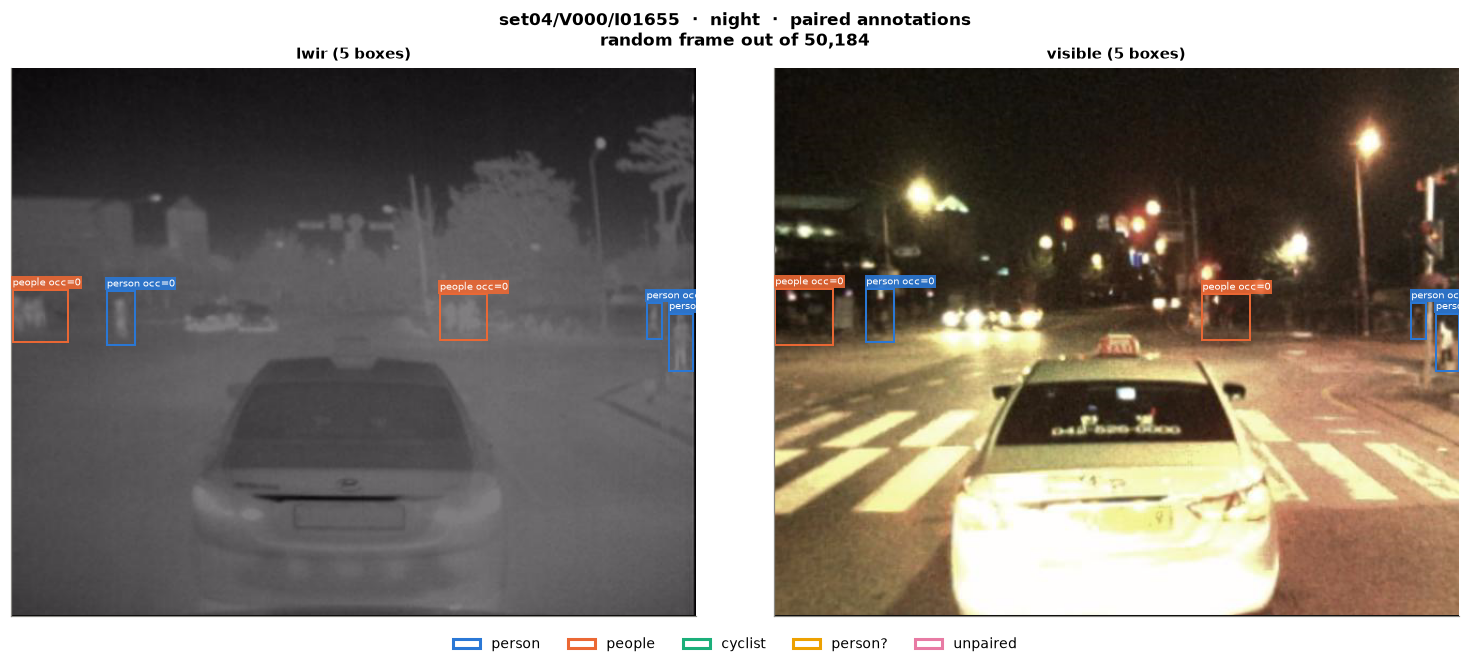

In [22]:
SEED = None

frame, n = sample(TRAIN, SEED)
show(frame, note=f"random frame out of {n:,}")

## 2. Random frame from a video window (`START`/`END` are inclusive 20 Hz frame indices, `None` = open end)

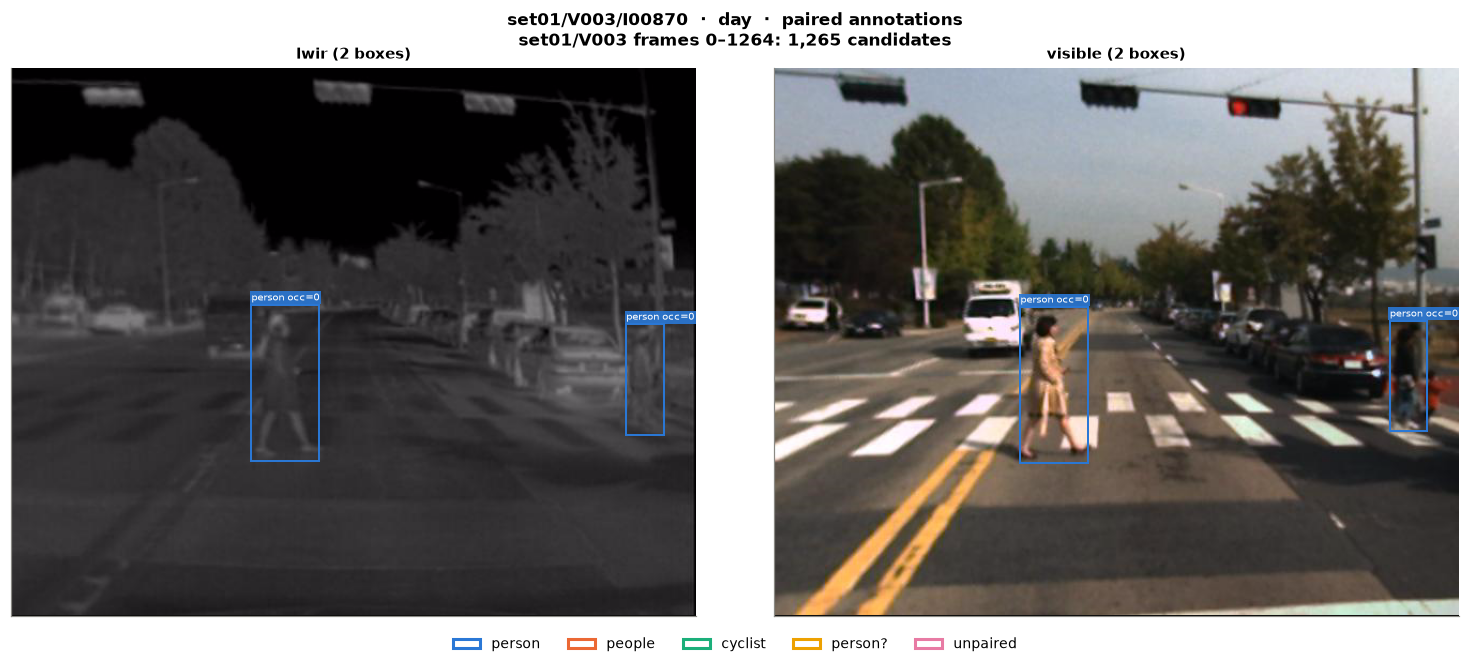

In [147]:
VIDEO = "set01/V003"
START, END = None, None
SEED = None

if VIDEO not in BY_VIDEO:
    raise ValueError(f"{VIDEO} is not a training video; choose from {sorted(BY_VIDEO)}")
idx = lambda f: int(f.rsplit("/I", 1)[1])
frames = [f for f in BY_VIDEO[VIDEO] if (START is None or idx(f) >= START) and (END is None or idx(f) <= END)]
frame, n = sample(frames, SEED)
show(frame, note=f"{VIDEO} frames {idx(BY_VIDEO[VIDEO][0]) if START is None else START}"
                 f"–{idx(BY_VIDEO[VIDEO][-1]) if END is None else END}: {n:,} candidates")

## 3. Random frame containing a given class (matching boxes drawn thick)

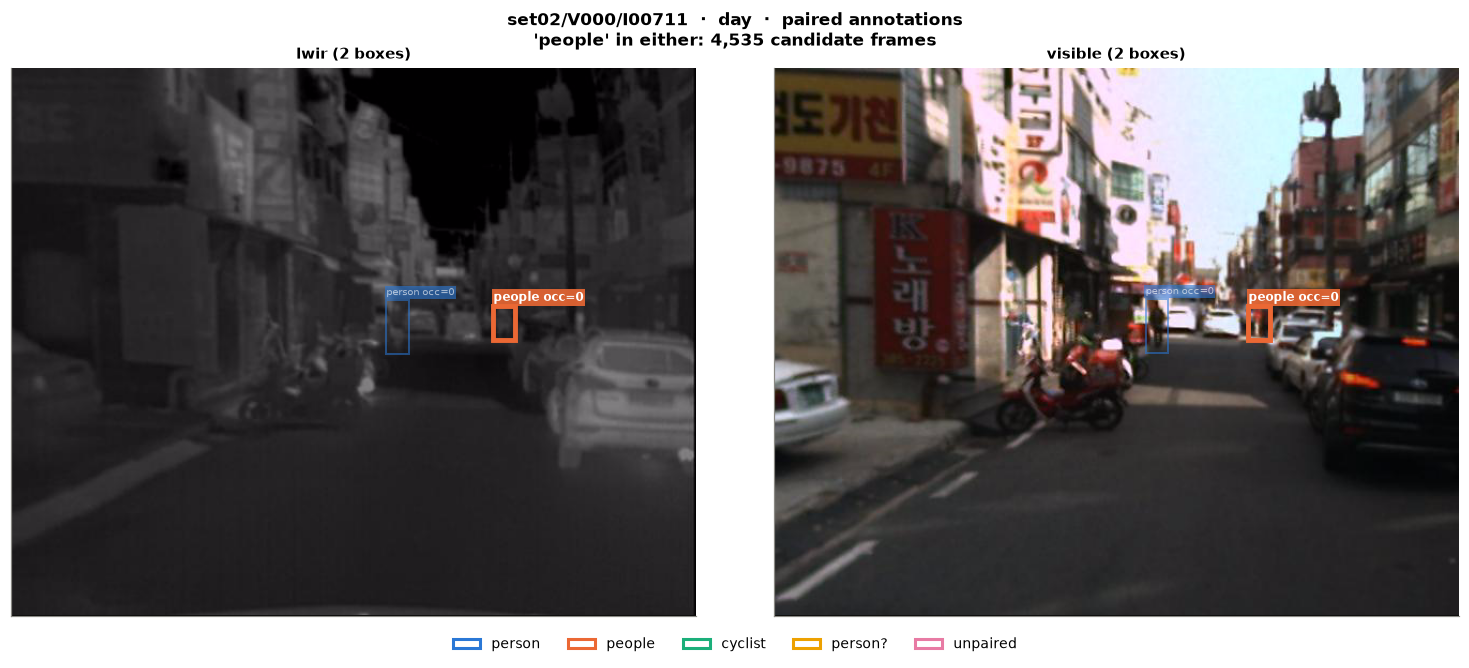

In [118]:
CLASS = "people"  # person, people, cyclist, person? (and unpaired for paired annotations)
MODALITY = "either"  # lwir / visible / either; paired only (original boxes are shared)
SEED = None

match = lambda m, b: m in mods_for(MODALITY) and b["label"] == CLASS
frames = [f for f in TRAIN if any(match(m, b) for m in MODS for b in ANN[f][m])]
frame, n = sample(frames, SEED)
show(frame, highlight=match, note=f"{CLASS!r} in {MODALITY}: {n:,} candidate frames")

## 4. Random frame containing a box with a given occlusion level (0 none, 1 partial, 2 heavy; matches drawn thick)

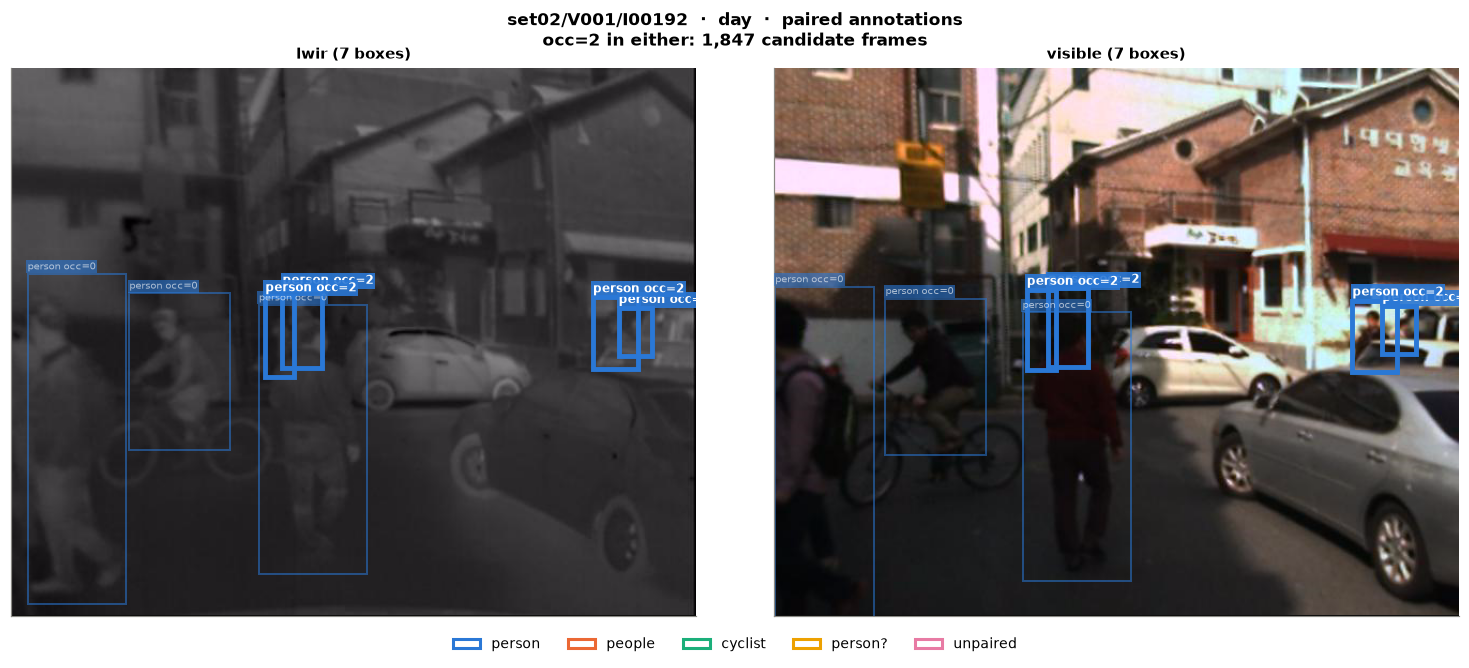

In [124]:
OCCLUSION = 2
MODALITY = "either"
SEED = None

match = lambda m, b: m in mods_for(MODALITY) and b["occ"] == OCCLUSION
frames = [f for f in TRAIN if any(match(m, b) for m in MODS for b in ANN[f][m])]
frame, n = sample(frames, SEED)
show(frame, highlight=match, note=f"occ={OCCLUSION} in {MODALITY}: {n:,} candidate frames")

## 5. Random unpaired box for one camera (paired annotations only; the chosen box is drawn thick)

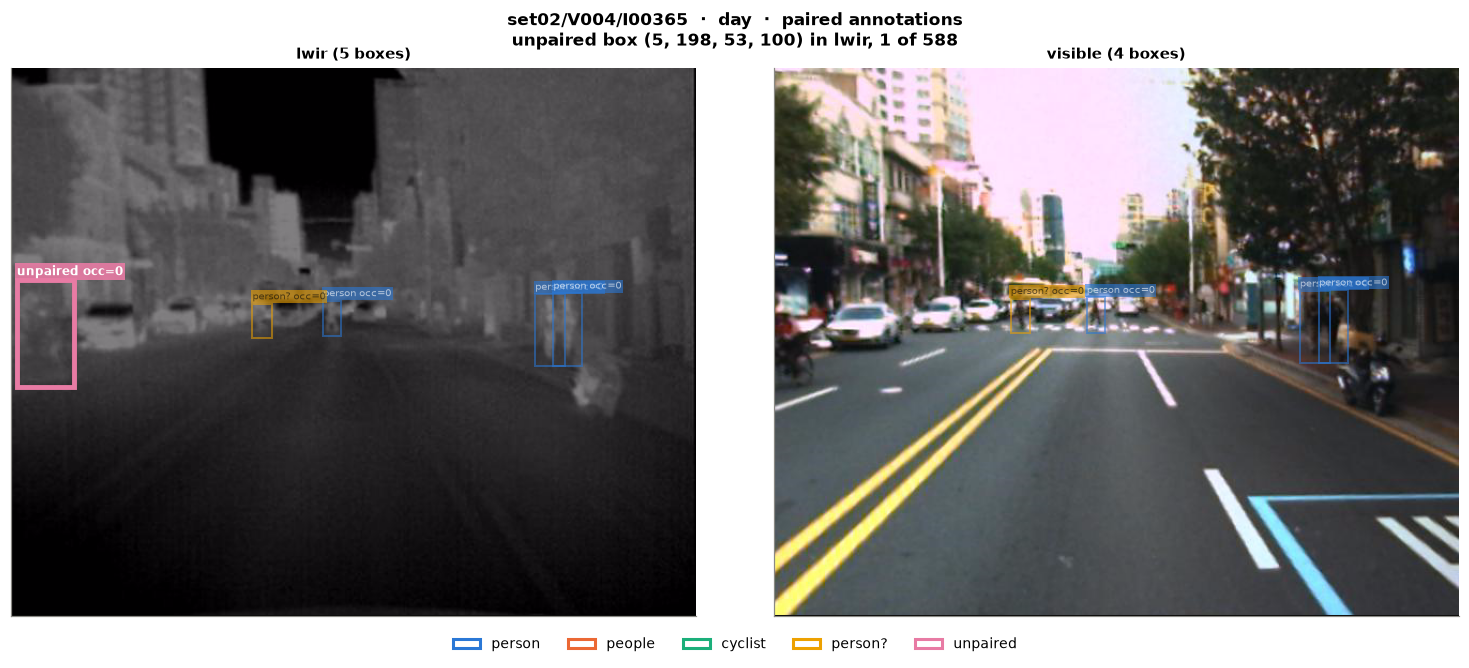

In [9]:
MODALITY = "lwir"  # lwir (588 train boxes) or visible (15)
SEED = None

if ANNOTATIONS != "paired":
    raise ValueError("'unpaired' boxes exist only in the paired annotations; set ANNOTATIONS = 'paired' and rerun")
assert MODALITY in MODS
cands = [(f, b) for f in TRAIN for b in ANN[f][MODALITY] if b["label"] == "unpaired"]
(frame, box), n = sample(cands, SEED)
show(frame, highlight=lambda m, b: m == MODALITY and b is box,
     note=f"unpaired box {box['xywh']} in {MODALITY}, 1 of {n:,}")